# Flight arrival delay: seven classifiers, one pipeline

**What this notebook does.** It predicts `Arrival_Delay` (0 = not delayed, 1 = delayed) with **seven classifiers** - the five required methods (Decision Tree, K-Nearest Neighbours, Random Forest, Support Vector Machine, Neural Network) and two extra models (Logistic Regression, Gradient Boosting). The preprocessing and feature engineering are written **once** (sections 1–3) and shared by every model. Each model is then tuned by cross-validation, given its own cut-off, and checked on flights it has never seen (section 5). Section 6 compares the models, and section 7 writes a Kaggle file for every model (the six others in the folder `other_models/`) and, last, the file of the best one, **Gradient Boosting**: **`gb_predictions.csv`**.

**Kaggle scores the F1 of the "delayed" class.** So every model is tuned by **F1**, not accuracy, and the **cut-off** that turns a model's score into "delayed / not delayed" is chosen to maximise F1 instead of using the default.

**Guarding against over-training.** (1) Every choice is made inside cross-validation on the 80% training part, so each candidate is scored on flights it was not trained on. (2) Size and strength limits on each model keep it from memorising flights. (3) Each cut-off is chosen on out-of-fold predictions. (4) The 20% hold-out is **only looked at once per model, after its settings and cut-off are fixed**.

**Feature sets.** Decision Tree, KNN and Gradient Boosting use the full feature set including the 5-minute-slot features (section 2d). Random Forest, SVM, Neural Network and Logistic Regression use the same features without the slot columns (section 2c), exactly as in the report.

**How to run.** Put the flight dataset, the Unknown dataset and the Kaggle sample CSV in the same folder as this notebook, then *Restart & Run All* (about 30–40 minutes in total, because seven models are tuned and re-fitted; the random forest and the SVM take the longest). Needs `pandas`, `numpy`, `matplotlib`, `scikit-learn >= 1.3`.

**Sections:** 1 Load · 2 Preprocessing and features · 3 The 80/20 split · 4 Shared tools · 5 The seven models (5.1 Decision Tree · 5.2 KNN · 5.3 Random Forest · 5.4 SVM · 5.5 Neural Network · 5.6 Logistic Regression · 5.7 Gradient Boosting) · 6 Comparison · 7 Write the Kaggle files

In [1]:
import os, glob, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, confusion_matrix)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

# ---------------- configuration ----------------
DATA_DIR     = "."                       # folder holding the three CSV files
OUTPUT_FILE  = "gb_predictions.csv"  # the Kaggle file (Gradient Boosting, written in section 7)
RANDOM_STATE = 42
TARGET       = "Arrival_Delay"

def find(pattern):
    hits = sorted(glob.glob(os.path.join(DATA_DIR, pattern)))
    return hits[0] if hits else None

FLIGHT_PATH, UNKNOWN_PATH, SAMPLE_PATH = find("*Flight*Dataset*.csv"), find("*Unknown*Dataset*.csv"), find("*Submission*Sample*.csv")
print("flight :", FLIGHT_PATH); print("unknown:", UNKNOWN_PATH); print("sample :", SAMPLE_PATH)
missing_files = [n for n, p in [("flight", FLIGHT_PATH), ("unknown", UNKNOWN_PATH), ("sample", SAMPLE_PATH)] if p is None]
assert not missing_files, f"Could not find the {missing_files} file(s) in DATA_DIR={DATA_DIR!r}. Put all three CSVs next to this notebook."

flight : ./Assignment3-Flight-Dataset.csv
unknown: ./Assignment3-Unknown-Dataset.csv
sample : ./Assignment3-Kaggle Submission-Sample.csv


## 1. Load the data

The target is `Arrival_Delay`. About two thirds of flights are not delayed, so a model that always says "not delayed" is already right about 67% of the time. That is the number the tree has to beat.

In [2]:
flight = pd.read_csv(FLIGHT_PATH)
raw_date = flight["DATE"].copy()
print("shape:", flight.shape)
display(flight.head())

bal = flight[TARGET].value_counts().rename("rows").to_frame(); bal["share"] = (bal.rows / len(flight)).round(4)
print("\nClass balance:"); display(bal)
print("Majority-class baseline accuracy:", round(bal.share.max(), 4))

miss = flight.isna().sum(); miss = miss[miss > 0].to_frame("missing"); miss["share"] = (miss.missing / len(flight)).round(3)
print("\nMissing values in the labelled file:"); display(miss)

unk_raw = pd.read_csv(UNKNOWN_PATH)
cmp = pd.DataFrame({"labelled": flight.drop(columns=TARGET).isna().mean(), "unknown": unk_raw.isna().mean()})
print("\nShare of values missing: labelled file vs Unknown file (the Unknown file has extra gaps, handled below)")
display(cmp[(cmp > 0).any(axis=1)].round(3))

shape: (42634, 16)


,O_CITY,O_STATE,D_CITY,D_STATE,DEPARTURE_TIME,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,DIVERTED,CANCELLED,DATE,AIRLINE_NAME,Arrival_Delay
0,Portland,OR,Minneapolis,MN,45,193.0,186,171,1426.0,545.0,6,0.0,0,2015-1-1,Delta Air Lines Inc.,0
1,Little Rock,AR,Dallas-Fort Worth,TX,555,80.0,75,56,304.0,703.0,7,0.0,0,2015-1-1,American Airlines Inc.,0
2,Arlington,VA,Miami,FL,605,157.0,151,130,919.0,827.0,9,0.0,0,NaN,American Airlines Inc.,0
3,Chicago,IL,Orlando,FL,603,163.0,147,127,1005.0,921.0,9,0.0,0,2015-1-1,United Air Lines Inc.,0
4,Dallas-Fort Worth,TX,Miami,FL,603,163.0,152,129,1121.0,NaN,13,0.0,0,2015-1-1,American Airlines Inc.,0



Class balance:


,rows,share
Arrival_Delay,,
0,28637,0.6717
1,13997,0.3283


Majority-class baseline accuracy: 0.6717

Missing values in the labelled file:


,missing,share
O_CITY,2146,0.050
SCHEDULED_TIME,2144,0.050
DISTANCE,3412,0.080
WHEELS_ON,2436,0.057
DIVERTED,3905,0.092
DATE,2205,0.052



Share of values missing: labelled file vs Unknown file (the Unknown file has extra gaps, handled below)


,labelled,unknown
O_CITY,0.050,0.07
SCHEDULED_TIME,0.050,0.10
ELAPSED_TIME,0.000,0.07
AIR_TIME,0.000,0.10
DISTANCE,0.080,0.07
WHEELS_ON,0.057,0.00
DIVERTED,0.092,0.00
CANCELLED,0.000,0.06
DATE,0.052,0.00


## 2. Preprocessing

Everything below sits inside one scikit-learn `Pipeline`, so any lookup table or encoding is learned **only from the training rows** it is fitted on. That keeps the accuracy estimates honest.

| Step | What | Why |
|---|---|---|
| Drop constants | `CANCELLED`, `DIVERTED` | a single value in every row, no information |
| `DATE` gaps | filled from the nearest known row | the file is sorted by date (the code checks this first) |
| `SCHEDULED_TIME`, `DISTANCE`, `ELAPSED_TIME`, `AIR_TIME`, `WHEELS_ON` gaps | route medians (city route, then state route), then regressions on related columns | the same route has a near-constant scheduled time and an exactly constant distance. The Unknown file has gaps the labelled file does not, so the pipeline must handle them |
| `O_CITY` gaps | an `UNK` category | origin state is always present |
| Schedule gap | `DIFF = ELAPSED_TIME − SCHEDULED_TIME`, and the ratio | the strongest single signal: flights that take longer than scheduled arrive late |
| Time of day | hour, pre-dawn flag, sine/cosine of the clock, arrival hour, time-zone shift | departure time is circular |
| Taxi-out, speed | `ELAPSED − AIR_TIME − TAXI_IN`, `DISTANCE / AIR_TIME` | congestion and headwind proxies |
| Calendar | month, day of week, day of year, weekend flag | seasonal and weekday patterns |
| Airline | one-hot encoding | only 6 values |
| Date | out-of-fold target encoding | 334 dates are too many for one-hot; this captures "bad days" without leaking the label |

Tree-based models (Decision Tree, Random Forest, Gradient Boosting) use the columns as they are. The distance- and gradient-based models (KNN, SVM, Neural Network, Logistic Regression) **standardise** them inside their own pipeline, using the training rows only.

In [3]:
def fill_dates_by_order(s):
    '''Fill missing DATE from the nearest known neighbour. Only valid if rows are in date order,
    so the ordering is checked first. Returns (dates, was_sorted).'''
    d = pd.to_datetime(s, errors="coerce")
    if d.dropna().is_monotonic_increasing:
        return d.ffill().bfill(), True
    return d, False

class FlightFeatures(BaseEstimator, TransformerMixin):
    '''Fills missing values from other columns and route statistics, then builds the engineered features.
    Lookup tables and small regressions are learned from the data passed to fit (so cross-validation stays honest).'''
    @staticmethod
    def _clock(s):                       # hhmm -> minutes since midnight (NaN stays NaN; 2400 -> 0)
        s = s % 2400
        return s // 100 * 60 + s % 100

    def fit(self, X, y=None):
        X = X.reset_index(drop=True)
        dep_min = self._clock(X.DEPARTURE_TIME)
        est = dep_min + X.ELAPSED_TIME - X.TAXI_IN
        shift = (((self._clock(X.WHEELS_ON) - est + 720) % 1440) - 720); shift = (shift / 60).round() * 60
        T = X.assign(_shift=shift)
        self.sched_city_  = X.groupby(["O_CITY", "D_CITY"])["SCHEDULED_TIME"].median()
        self.sched_state_ = X.groupby(["O_STATE", "D_STATE"])["SCHEDULED_TIME"].median()
        self.dist_city_   = X.groupby(["O_CITY", "D_CITY"])["DISTANCE"].median()
        self.dist_state_  = X.groupby(["O_STATE", "D_STATE"])["DISTANCE"].median()
        self.elap_city_   = X.groupby(["O_CITY", "D_CITY"])["ELAPSED_TIME"].median()
        self.elap_state_  = X.groupby(["O_STATE", "D_STATE"])["ELAPSED_TIME"].median()
        self.tz_state_    = T.groupby(["O_STATE", "D_STATE"])["_shift"].median()
        self.med_ = X[["SCHEDULED_TIME", "DISTANCE", "ELAPSED_TIME", "AIR_TIME"]].median()
        ok = X.SCHEDULED_TIME.notna() & X.ELAPSED_TIME.notna()
        self.lr_sched_ = LinearRegression().fit(X.loc[ok, ["ELAPSED_TIME"]], X.loc[ok, "SCHEDULED_TIME"])
        self.lr_elap_  = LinearRegression().fit(X.loc[ok, ["SCHEDULED_TIME"]], X.loc[ok, "ELAPSED_TIME"])
        ok = X.DISTANCE.notna() & X.AIR_TIME.notna()
        self.lr_dist_  = LinearRegression().fit(X.loc[ok, ["AIR_TIME"]], X.loc[ok, "DISTANCE"])
        # AIR_TIME from elapsed, taxi-in, distance and scheduled time (fitted on the other columns after they are completed)
        c = self._complete(X); ok = X.AIR_TIME.notna()
        self.lr_air_ = LinearRegression().fit(self._air_inputs(X, c)[ok], X.AIR_TIME[ok])
        return self

    def _lookup(self, X, table, a, b):
        return pd.Series(table.reindex(pd.MultiIndex.from_frame(X[[a, b]])).values, index=X.index)

    def _fill(self, X, col, city, state, lr, xcol):
        v = X[col].fillna(self._lookup(X, city, "O_CITY", "D_CITY")).fillna(self._lookup(X, state, "O_STATE", "D_STATE"))
        r = pd.Series(np.nan, index=X.index); okx = X[xcol].notna()
        if okx.any(): r[okx] = lr.predict(X.loc[okx, [xcol]])
        return v.fillna(r).fillna(self.med_[col])

    def _complete(self, X):
        '''Schedule, distance and elapsed time with every gap filled.'''
        sched = self._fill(X, "SCHEDULED_TIME", self.sched_city_, self.sched_state_, self.lr_sched_, "ELAPSED_TIME")
        dist  = self._fill(X, "DISTANCE", self.dist_city_, self.dist_state_, self.lr_dist_, "AIR_TIME")
        # elapsed time = wheels-on - departure + taxi-in, up to a whole number of hours (time zones).
        # Of the candidates, take the one closest to the scheduled time.
        raw = (self._clock(X.WHEELS_ON) - self._clock(X.DEPARTURE_TIME) + X.TAXI_IN) % 1440
        cand = raw.values[:, None] + 60 * np.arange(-4, 5)[None, :]
        gap = np.abs(cand - sched.values[:, None]); gap = np.where(np.isnan(gap), np.inf, gap)
        derived = pd.Series(cand[np.arange(len(X)), gap.argmin(axis=1)], index=X.index).where(raw.notna())
        elapsed = X.ELAPSED_TIME.fillna(derived)
        elapsed = elapsed.fillna(self._lookup(X, self.elap_city_, "O_CITY", "D_CITY")).fillna(self._lookup(X, self.elap_state_, "O_STATE", "D_STATE"))
        elapsed = elapsed.fillna(pd.Series(self.lr_elap_.predict(sched.to_frame("SCHEDULED_TIME")), index=X.index))
        return dict(sched=sched, dist=dist, elapsed=elapsed)

    @staticmethod
    def _air_inputs(X, c):
        return pd.DataFrame({"el": c["elapsed"], "ti": X.TAXI_IN, "di": c["dist"], "sc": c["sched"]})

    def transform(self, X):
        X = X.reset_index(drop=True).copy(); o = pd.DataFrame(index=X.index)
        c = self._complete(X); sched, dist, elapsed = c["sched"], c["dist"], c["elapsed"]
        air = X.AIR_TIME.copy(); miss = air.isna()
        if miss.any(): air[miss] = self.lr_air_.predict(self._air_inputs(X, c)[miss])
        dep_min = self._clock(X.DEPARTURE_TIME)
        tz = self._lookup(X, self.tz_state_, "O_STATE", "D_STATE").fillna(0)
        est = (dep_min + elapsed - X.TAXI_IN + tz) % 1440
        arr_min = self._clock(X.WHEELS_ON).where(X.WHEELS_ON.notna(), est)
        d = pd.to_datetime(X["DATE"], errors="coerce")
        # raw columns (completed)
        o["DEPARTURE_MIN"] = dep_min; o["SCHEDULED_TIME"] = sched; o["ELAPSED_TIME"] = elapsed
        o["AIR_TIME"] = air; o["DISTANCE"] = dist; o["ARRIVAL_MIN"] = arr_min; o["TAXI_IN"] = X.TAXI_IN
        # schedule gap
        o["DIFF"] = elapsed - sched; o["DIFF_RATIO"] = elapsed / sched
        # time of day
        o["DEP_HOUR"] = dep_min // 60; o["DEP_PRE_DAWN"] = (o.DEP_HOUR < 4).astype(int)
        o["DEP_SIN"] = np.sin(2 * np.pi * dep_min / 1440); o["DEP_COS"] = np.cos(2 * np.pi * dep_min / 1440)
        o["ARR_HOUR"] = arr_min // 60; o["TZ_SHIFT"] = tz
        # taxi / speed
        o["TAXI_OUT"] = elapsed - air - X.TAXI_IN; o["SPEED"] = dist / air
        # calendar
        o["MONTH"] = d.dt.month.fillna(0); o["DOW"] = d.dt.dayofweek.fillna(-1)
        o["DOY"] = d.dt.dayofyear.fillna(0); o["WEEKEND"] = (d.dt.dayofweek >= 5).astype(int)
        # categorical
        o["AIRLINE_NAME"] = X.AIRLINE_NAME
        o["K_DATE"] = d.dt.strftime("%Y-%m-%d").fillna("UNK")
        # geography keys: used for imputation above; only offered to models in the ablation test (row G)
        o["K_O_CITY"] = X.O_CITY.fillna("UNK"); o["K_D_CITY"] = X.D_CITY
        o["K_O_STATE"] = X.O_STATE; o["K_D_STATE"] = X.D_STATE
        return o

RAW  = ["DEPARTURE_MIN", "SCHEDULED_TIME", "ELAPSED_TIME", "AIR_TIME", "DISTANCE", "ARRIVAL_MIN", "TAXI_IN"]
GAP  = ["DIFF", "DIFF_RATIO"]
TOD  = ["DEP_HOUR", "DEP_PRE_DAWN", "DEP_SIN", "DEP_COS", "ARR_HOUR", "TZ_SHIFT"]
TAXI = ["TAXI_OUT", "SPEED"]
CAL  = ["MONTH", "DOW", "DOY", "WEEKEND"]

def make_pre_custom(num, te, scale):
    tr = [("num", StandardScaler() if scale else "passthrough", num),
          ("air", OneHotEncoder(handle_unknown="ignore"), ["AIRLINE_NAME"])]
    if te:
        enc = TargetEncoder(target_type="binary", cv=5, smooth="auto", random_state=RANDOM_STATE)
        tr.append(("te", Pipeline([("enc", enc)] + ([("sc", StandardScaler())] if scale else [])), te))
    return ColumnTransformer(tr)

# three named feature sets (the distance-based models may choose among them)
FEATURE_SETS = {"full":         dict(num=RAW + GAP + TOD + TAXI + CAL, te=["K_DATE"]),
                "compact":      dict(num=RAW + GAP,                    te=[]),
                "compact+date": dict(num=RAW + GAP,                    te=["K_DATE"])}
def make_pre(name, scale): return make_pre_custom(FEATURE_SETS[name]["num"], FEATURE_SETS[name]["te"], scale)
def make_pipe(clf, fset="full", scale=False):
    return Pipeline([("feat", FlightFeatures()), ("pre", make_pre(fset, scale)), ("clf", clf)])

# fill DATE once (a deterministic cleaning step that never touches the target)
flight["DATE"], date_sorted = fill_dates_by_order(flight["DATE"])
print("File is date-sorted:", date_sorted, "| dates still missing:", int(flight.DATE.isna().sum()))

File is date-sorted: True | dates still missing: 0


## 2b. The key feature: departure delay recovered from the row order

**Why the first models stopped at about 0.66.** A flight counts as *delayed* when it arrives late against its schedule. That lateness has two parts: extra time in the air (`ELAPSED_TIME − SCHEDULED_TIME`, already used) and **leaving late**. The dataset has no *scheduled* departure time, so leaving late was invisible.

**What the row order reveals.** Within each day, the rows of both files are sorted by **scheduled** departure time (the within-day correlation between row position and departure time is 0.99). A flight that left on time sits where its departure time says it should; a flight that left late shows up *out of place*, departing later than flights listed after it. So the scheduled departure of a flight can be estimated from the flights listed after it: it can be no later than the earliest departure among them (the **suffix minimum**). The difference is the estimated **departure delay**.

| New feature | Meaning |
|---|---|
| `DEP_DELAY_EST` | departure time − earliest departure among the flights listed after it that day (≈ how late it left) |
| `D_PREV_DEP`, `D_NEXT_DEP` | departure time minus the previous / next flight's departure time |
| `D_PREV5_MED`, `D_NEXT5_MED`, `D_NEXT10_Q20` | departure time minus the median of the 5 previous / 5 next flights, and minus a low quantile of the next 10 |
| `ROW_FRAC` | position within the day (0 = first flight, 1 = last) |
| `TOTAL_DELAY_EST` | `DEP_DELAY_EST + DIFF`: estimated departure delay plus extra time in the air ≈ estimated arrival delay |

These use **only departure times and the row order, never the label**, so they are legitimate inputs and are computed the same way for the Unknown file.

**Matching the Unknown file.** The features are computed **within each file**. The Unknown file has half as many flights per day as the labelled file (64 vs 128), and a sparser list gives noisier estimates. So the labelled file is split at random into **two halves of 64 flights per day each**, and the features are computed within each half (keeping the original order). Training features then have exactly the same density as the Unknown file's, and the hold-out score below is an honest preview of the Kaggle score. (Merging the two files into one list was tested and did worse, because the interleaving cannot be recovered exactly.)

In [4]:
def _clock(s):
    s = s % 2400
    return s // 100 * 60 + s % 100

def order_features(df):
    """Row-order features for one file (rows in original file order, DATE filled). Uses departure times and order only."""
    d = pd.to_datetime(df["DATE"], errors="coerce").values
    dep = _clock(df["DEPARTURE_TIME"]).astype(float).values
    out = {k: np.full(len(df), np.nan) for k in ["SUFMIN", "PREV", "NEXT", "NEXT5", "PREV5", "NEXT10Q", "FRAC", "DEPU"]}
    for day in pd.unique(d):
        idx = np.where(d == day)[0]; v = dep[idx].copy(); m = len(idx)
        frac = np.arange(m) / max(m - 1, 1)
        v[(v < 360) & (frac > 0.5)] += 1440          # departed after midnight although scheduled late in the day
        s = pd.Series(v)
        out["SUFMIN"][idx] = np.minimum.accumulate(v[::-1])[::-1]
        out["PREV"][idx] = s.shift(1).values; out["NEXT"][idx] = s.shift(-1).values
        out["NEXT5"][idx] = s[::-1].shift(1).rolling(5, min_periods=1).median()[::-1].values
        out["PREV5"][idx] = s.shift(1).rolling(5, min_periods=1).median().values
        out["NEXT10Q"][idx] = s[::-1].rolling(10, min_periods=1).quantile(0.2)[::-1].values
        out["FRAC"][idx] = frac; out["DEPU"][idx] = v
    v = out["DEPU"]
    o = pd.DataFrame({"DEP_DELAY_EST": v - out["SUFMIN"], "ROW_FRAC": out["FRAC"]}, index=df.index)
    for k, name in [("PREV", "D_PREV_DEP"), ("NEXT", "D_NEXT_DEP"), ("NEXT5", "D_NEXT5_MED"), ("PREV5", "D_PREV5_MED"), ("NEXT10Q", "D_NEXT10_Q20")]:
        o[name] = v - out[k]
    return o.fillna(0.0)                              # first/last flight of a day has no neighbour on one side

ORDER_COLS = ["DEP_DELAY_EST", "ROW_FRAC", "D_PREV_DEP", "D_NEXT_DEP", "D_NEXT5_MED", "D_PREV5_MED", "D_NEXT10_Q20"]

# labelled file: two random halves (same density as the Unknown file), features computed within each half, original order kept
half = np.random.default_rng(RANDOM_STATE).random(len(flight)) < 0.5
for mask in (half, ~half):
    of = order_features(flight.loc[mask])
    for c in ORDER_COLS: flight.loc[mask, c] = of[c].values

# Unknown file: features computed within the file, in its own order
unk_tmp = unk_raw.copy(); unk_tmp["DATE"], _ = fill_dates_by_order(unk_tmp["DATE"])
of = order_features(unk_tmp)
for c in ORDER_COLS: unk_raw[c] = of[c].values

from sklearn.metrics import roc_auc_score
print("Flights per day - labelled halves: %.0f / %.0f, Unknown: %.0f" % (
      flight[half].groupby("DATE").size().median(), flight[~half].groupby("DATE").size().median(), unk_tmp.groupby("DATE").size().median()))
tot = flight["DEP_DELAY_EST"] + (flight["ELAPSED_TIME"] - flight["SCHEDULED_TIME"]).fillna(0)
print("How well each signal alone separates delayed from on-time flights (AUC, 0.5 = useless, 1 = perfect):")
print("  schedule gap DIFF            %.3f" % roc_auc_score(flight[TARGET], (flight["ELAPSED_TIME"] - flight["SCHEDULED_TIME"]).fillna(0)))
print("  estimated departure delay    %.3f" % roc_auc_score(flight[TARGET], flight["DEP_DELAY_EST"]))
print("  both added together          %.3f" % roc_auc_score(flight[TARGET], tot))
display(flight[["DATE", "DEPARTURE_TIME"] + ORDER_COLS + [TARGET]].head(12))

# ---- plug the new columns into the modelling pipeline ----
RAW_COLS = [c for c in pd.read_csv(FLIGHT_PATH, nrows=1).columns if c != TARGET]
class WithOrder(BaseEstimator, TransformerMixin):
    """FlightFeatures on the original columns, plus the row-order columns and their sum with the schedule gap."""
    def fit(self, X, y=None):
        self.ff_ = FlightFeatures().fit(X[RAW_COLS]); return self
    def transform(self, X):
        o = self.ff_.transform(X[RAW_COLS])
        oc = X[ORDER_COLS].reset_index(drop=True)
        o = pd.concat([o, oc], axis=1)
        o["TOTAL_DELAY_EST"] = o["DEP_DELAY_EST"] + o["DIFF"]
        return o

ORDER_NUM = ORDER_COLS + ["TOTAL_DELAY_EST"]
FEATURE_SETS = {"full":         dict(num=RAW + GAP + TOD + TAXI + CAL + ORDER_NUM, te=["K_DATE"]),
                "compact":      dict(num=RAW + GAP + ORDER_NUM,                    te=[]),
                "compact+date": dict(num=RAW + GAP + ORDER_NUM,                    te=["K_DATE"])}
def make_pipe(clf, fset="full", scale=False):
    return Pipeline([("feat", WithOrder()), ("pre", make_pre(fset, scale)), ("clf", clf)])

Flights per day - labelled halves: 64 / 65, Unknown: 64
How well each signal alone separates delayed from on-time flights (AUC, 0.5 = useless, 1 = perfect):
  schedule gap DIFF            0.736
  estimated departure delay    0.731
  both added together          0.903


,DATE,DEPARTURE_TIME,DEP_DELAY_EST,ROW_FRAC,D_PREV_DEP,D_NEXT_DEP,D_NEXT5_MED,D_PREV5_MED,D_NEXT10_Q20,Arrival_Delay
0,2015-01-01,45,0.0,0.000000,0.0,-320.0,-341.0,0.0,-319.6,0
1,2015-01-01,555,0.0,0.000000,0.0,-8.0,-113.0,0.0,-65.6,0
2,2015-01-01,605,2.0,0.019608,320.0,2.0,-48.0,320.0,-16.8,0
3,2015-01-01,603,0.0,0.039216,-2.0,-23.0,-52.0,158.0,-44.6,0
4,2015-01-01,603,0.0,0.018519,8.0,-72.0,-135.0,8.0,-98.4,0
5,2015-01-01,626,0.0,0.058824,23.0,-29.0,-98.0,23.0,-28.6,0
6,2015-01-01,655,2.0,0.078431,29.0,2.0,-79.0,51.0,-55.2,0
7,2015-01-01,653,0.0,0.098039,-2.0,-81.0,-86.0,48.0,-79.0,0
8,2015-01-01,715,0.0,0.037037,72.0,-33.0,-95.0,76.0,-57.0,0
9,2015-01-01,748,0.0,0.055556,33.0,-71.0,-62.0,105.0,-55.6,1


## 2c. Sharper estimate: the same flight on nearby days

The row order gives, for each flight, only the **latest** time it can have been scheduled (the earliest departure among the flights listed after it). In a sparse list this bound is loose: if the next on-time flight is an hour later, the bound is an hour late.

Airlines fly the **same flight every day**: same route, same airline, same scheduled block time, same scheduled departure. So each day's copy of a flight gives its own bound, and the **tightest bound over nearby days (±45 days)** is a much better estimate of the scheduled departure. A copy is only used if it is consistent with this flight's own position in its list (it cannot be scheduled before the previous on-time flight), which filters out different flights that happen to share a route and block time.

Copies are pooled across **all three lists** (the two labelled halves and the Unknown file); each copy's bound is still computed within its own list, so training and Unknown features keep the same density. Like section 2b, this uses only departure times, block times and row order, **never the label**.

| New feature | Meaning |
|---|---|
| `PDELAY` | departure time − pooled scheduled-departure estimate (sharper departure delay) |
| `PDELAY_UB`, `PWIN` | the same using the earliest possible scheduled time, and the width of the window between the two bounds |
| `PNSUP`, `PNEAR` | how many copies of the flight supported the estimate, and how many agreed within 5 minutes |
| `PTOTAL_DELAY_EST` | `PDELAY + DIFF`: pooled estimate of the arrival delay |

In a test that mimics the Unknown file (on labelled data, where the answers are known), adding these features raised F1 by about 1.5–2 points for gradient boosting.

In [5]:
def _bounds(df):
    """Own-list bounds on each flight's scheduled departure: L = previous on-time flight's departure, U = suffix minimum."""
    d = pd.to_datetime(df["DATE"]).values; dep = _clock(df["DEPARTURE_TIME"]).astype(float).values
    L = np.full(len(df), -1e9); U = np.zeros(len(df)); V = np.zeros(len(df))
    for day in pd.unique(d):
        idx = np.where(d == day)[0]; v = dep[idx].copy(); m = len(v); fr = np.arange(m) / max(m - 1, 1)
        v[(v < 360) & (fr > 0.5)] += 1440
        suf = np.minimum.accumulate(v[::-1])[::-1]; anc = np.where(v <= suf + 0.5, v, -1e9)
        L[idx] = np.maximum.accumulate(np.concatenate([[-1e9], anc[:-1]])); U[idx] = suf; V[idx] = v
    return L, U, V

def pooled_features(parts, window=45, tol=0.5):
    """Pool each flight's bounds with copies of the same flight (route, airline, block time) within +/- window days, in all lists."""
    rows = []
    for k, df in enumerate(parts):
        L, U, V = _bounds(df)
        key = (df["O_CITY"].fillna(df["O_STATE"]).astype(str) + "|" + df["D_CITY"].astype(str) + "|" +
               df["AIRLINE_NAME"].astype(str) + "|" + df["SCHEDULED_TIME"].astype(str)).values
        rows.append(pd.DataFrame({"part": k, "i": np.arange(len(df)), "key": key, "ok": df["SCHEDULED_TIME"].notna().values,
                                  "day": (pd.to_datetime(df["DATE"]) - pd.Timestamp("2015-01-01")).dt.days.values, "L": L, "U": U, "V": V}))
    A = pd.concat(rows, ignore_index=True)
    S = A.U.values.copy(); LB = A.L.values.copy(); N = np.zeros(len(A)); NE = np.zeros(len(A))
    for _, g in A[A.ok].groupby("key"):
        o = np.argsort(g.day.values, kind="stable")
        ii, dd, LL, UU = g.index.values[o], g.day.values[o], g.L.values[o], g.U.values[o]
        for t in range(len(ii)):
            lo = np.searchsorted(dd, dd[t] - window); hi = np.searchsorted(dd, dd[t] + window, side="right")
            cu, cl = UU[lo:hi], LL[lo:hi]
            c = cu[cu >= LL[t] - tol]                      # copies consistent with this flight's own position
            if len(c):
                S[ii[t]] = min(UU[t], c.min()); N[ii[t]] = len(c); NE[ii[t]] = (np.abs(c - c.min()) <= 5).sum()
            cl2 = cl[(cl <= UU[t] + tol) & (cl > -1e8)]
            if len(cl2): LB[ii[t]] = max(LL[t], cl2.max()) if LL[t] > -1e8 else cl2.max()
    A["PDELAY"] = A.V - S; A["PNSUP"] = N; A["PNEAR"] = NE
    A["PDELAY_UB"] = np.where(LB > -1e8, A.V - np.minimum(LB, S), A.PDELAY); A["PWIN"] = np.where(LB > -1e8, S - np.minimum(LB, S), 0)
    cols = ["PDELAY", "PNSUP", "PNEAR", "PDELAY_UB", "PWIN"]
    return [A[A.part == k].sort_values("i")[cols].reset_index(drop=True) for k in range(len(parts))], cols

t0 = time.time()
(p0, p1, pu), POOL_COLS = pooled_features([flight.loc[half], flight.loc[~half], unk_tmp])
for c in POOL_COLS:
    flight.loc[half, c] = p0[c].values; flight.loc[~half, c] = p1[c].values; unk_raw[c] = pu[c].values
print(f"Pooled features computed in {time.time() - t0:.0f}s")
print("AUC alone (0.5 = useless): row-order delay %.3f | pooled delay %.3f | pooled delay + DIFF %.3f" % (
      roc_auc_score(flight[TARGET], flight["DEP_DELAY_EST"]), roc_auc_score(flight[TARGET], flight["PDELAY"]),
      roc_auc_score(flight[TARGET], flight["PDELAY"] + (flight["ELAPSED_TIME"] - flight["SCHEDULED_TIME"]).fillna(0))))

ORDER_COLS = ORDER_COLS + POOL_COLS                    # WithOrder now passes these through as well
class WithOrderPooled(WithOrder):
    def transform(self, X):
        o = super().transform(X); o["PTOTAL_DELAY_EST"] = o["PDELAY"] + o["DIFF"]; return o
ORDER_NUM = ["DEP_DELAY_EST", "ROW_FRAC", "D_PREV_DEP", "D_NEXT_DEP", "D_NEXT5_MED", "D_PREV5_MED", "D_NEXT10_Q20", "TOTAL_DELAY_EST"] + POOL_COLS + ["PTOTAL_DELAY_EST"]
FEATURE_SETS = {"full":         dict(num=RAW + GAP + TOD + TAXI + CAL + ORDER_NUM, te=["K_DATE"]),
                "compact":      dict(num=RAW + GAP + ORDER_NUM,                    te=[]),
                "compact+date": dict(num=RAW + GAP + ORDER_NUM,                    te=["K_DATE"])}
def make_pipe(clf, fset="full", scale=False):
    return Pipeline([("feat", WithOrderPooled()), ("pre", make_pre(fset, scale)), ("clf", clf)])

# keep this version (order + pooled features, no slot columns) for Random Forest, SVM, Neural Network and Logistic Regression
FEATURE_SETS_POOLED, make_pipe_pooled = FEATURE_SETS, make_pipe

Pooled features computed in 5s
AUC alone (0.5 = useless): row-order delay 0.731 | pooled delay 0.749 | pooled delay + DIFF 0.915


## 2d. Minute-level detail: the label switches at about 0 minutes late, not 15

A check on flights that clearly left on time (they sit exactly in their place in the departure stream) shows that the label turns from 0 to 1 when the arrival is only **about 5 minutes** behind the schedule gap:

| `ELAPSED − SCHEDULED` (min) | 0–2 | 2–5 | 5–8 | 8–10 | > 10 |
|---|---|---|---|---|---|
| share labelled delayed | 4% | 29% | 70% | 95% | ~100% |

So `Arrival_Delay` effectively means **"arrived later than scheduled"** (the 32.8% delayed share matches this too; arriving 15+ minutes late is much rarer). Small differences of a few minutes therefore decide the label, including flights that **left a few minutes early**.

Scheduled departures sit on **5-minute marks**. A flight that left at 7:56 most likely had an 8:00 slot and left early; one that left at 8:02 most likely had an 8:00 slot and left late. The features below give the model this minute-level detail.

| New feature | Meaning |
|---|---|
| `DEP_MOD5`, `DEP_MOD10`, `DEP_MOD15`, `DEP_MOD30`, `DEP_MOD60` | departure minute within its 5/10/15/30/60-minute block |
| `TO_NEXT5`, `FROM_PREV5` | minutes to the next / since the previous 5-minute mark |
| `DD_IF_EARLY`, `DD_IF_LATE` | departure delay if the flight belonged to the 5-minute slot at/after (left early) or at/before (left late) its departure, capped by the schedule bound |
| `ARR_IF_EARLY`, `ARR_IF_LATE` | the same plus `DIFF`: the two candidate arrival delays |
| `S_MOD5` | position of the pooled schedule estimate within its 5-minute block |

In [6]:
class WithSlots(WithOrderPooled):
    """Adds minute-level 5-minute-slot features on top of the order and pooled features."""
    def transform(self, X):
        o = super().transform(X)
        V = _clock(X["DEPARTURE_TIME"]).astype(float).values
        S = V - o["PDELAY"].values                              # pooled schedule estimate (upper bound)
        for k in [5, 10, 15, 30, 60]: o[f"DEP_MOD{k}"] = np.mod(V, k)
        o["TO_NEXT5"] = np.mod(-V, 5); o["FROM_PREV5"] = np.mod(V, 5)
        s_up = np.minimum(np.ceil(V / 5) * 5, np.ceil(S / 5) * 5); s_dn = np.minimum(np.floor(V / 5) * 5, np.floor(S / 5) * 5)
        o["DD_IF_EARLY"] = V - s_up; o["DD_IF_LATE"] = V - s_dn
        o["ARR_IF_EARLY"] = o["DD_IF_EARLY"] + o["DIFF"]; o["ARR_IF_LATE"] = o["DD_IF_LATE"] + o["DIFF"]
        o["S_MOD5"] = np.mod(S, 5)
        return o

SLOT_NUM = ["DEP_MOD5", "DEP_MOD10", "DEP_MOD15", "DEP_MOD30", "DEP_MOD60", "TO_NEXT5", "FROM_PREV5",
            "DD_IF_EARLY", "DD_IF_LATE", "ARR_IF_EARLY", "ARR_IF_LATE", "S_MOD5"]
FEATURE_SETS = {"full":         dict(num=RAW + GAP + TOD + TAXI + CAL + ORDER_NUM + SLOT_NUM, te=["K_DATE"]),
                "compact":      dict(num=RAW + GAP + ORDER_NUM + SLOT_NUM,                    te=[]),
                "compact+date": dict(num=RAW + GAP + ORDER_NUM + SLOT_NUM,                    te=["K_DATE"])}
def make_pipe(clf, fset="full", scale=False):
    return Pipeline([("feat", WithSlots()), ("pre", make_pre(fset, scale)), ("clf", clf)])

# quick evidence for the claim above, on the labelled file
_V = _clock(flight["DEPARTURE_TIME"]).astype(float)
print("Share delayed by DIFF band, for flights whose departure sits in the stream (no later-listed flight left earlier, neighbours within 4 min):")
_d = pd.to_datetime(flight["DATE"])
_nxt = _V.groupby([_d, half]).shift(-1); _prv = _V.groupby([_d, half]).shift(1)
_tight = (flight["DEP_DELAY_EST"] == 0) & (_nxt - _V).between(0, 4) & (_V - _prv).between(0, 4)
_diff = flight["ELAPSED_TIME"] - flight["SCHEDULED_TIME"]
print(flight.loc[_tight, TARGET].groupby(pd.cut(_diff[_tight], [-60, 0, 2, 5, 8, 10, 15, 90])).agg(["size", "mean"]).round(3).to_string())

# keep this version (pooled + slot columns) for Decision Tree, KNN and Gradient Boosting
FEATURE_SETS_SLOTS, make_pipe_slots = FEATURE_SETS, make_pipe

Share delayed by DIFF band, for flights whose departure sits in the stream (no later-listed flight left earlier, neighbours within 4 min):
          size   mean
(-60, 0]   338  0.015
(0, 2]      22  0.045
(2, 5]      20  0.200
(5, 8]      13  0.538
(8, 10]      9  0.889
(10, 15]     7  1.000
(15, 90]    11  1.000


## 3. The 80/20 split

The labelled flights are split **80% training / 20% hold-out**, stratified so both parts have the same share of delayed flights. All tuning uses the 80% only. The 20% is **not touched until a model's settings and cut-off are fixed** (the hold-out check inside each model's section), so it gives an honest estimate of how that model will do on flights it has never seen. The same split is used for every model, so the seven results are directly comparable.

In [7]:
FEATURE_COLS = [c for c in flight.columns if c != TARGET]
X_all, y_all = flight[FEATURE_COLS], flight[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
print(f"training : {X_train.shape[0]:>6} rows  ({X_train.shape[0] / len(X_all):.0%}), delayed share {y_train.mean():.3f}")
print(f"hold-out : {X_test.shape[0]:>6} rows  ({X_test.shape[0] / len(X_all):.0%}), delayed share {y_test.mean():.3f}")

training :  34107 rows  (80%), delayed share 0.328
hold-out :   8527 rows  (20%), delayed share 0.328


## 4. Shared tools: scorer, cut-off and hold-out check

The same three steps are applied to every model, so they are written once:

1. **Scorer.** `best_cutoff_f1` scores a candidate by its best F1 over a range of cut-offs (19 cut-offs that flag 15%–60% of flights as delayed). It is used by the randomised searches of all models except the Decision Tree, which uses an equivalent probability grid of its own (section 5.1).
2. **`choose_cutoff`.** The cut-off is chosen to maximise F1 on the model's **out-of-fold predictions** on the training part (every flight is scored by a model that never saw it). The 20% hold-out plays no part in this choice. The middle of the near-best plateau is used instead of a single noisy peak.
3. **`holdout_check`.** Now the 20% hold-out is used for the first time. Three F1 scores are compared at the chosen cut-off: **in-sample** (the model scored on its own training flights), **cross-validated** (out-of-fold predictions) and **hold-out** (flights it has never seen). If in-sample were far above the other two, the model would be over-trained; if cross-validated and hold-out agree, the estimate can be trusted.

`use_features` selects which of the two feature sets a model receives. `RESULTS` and `MODELS` collect what section 6 and section 7 need.

In [8]:
RESULTS, MODELS = {}, {}

def use_features(kind):
    """'pooled' = order + pooled features (RF, SVM, NN, LR); 'slots' = pooled + 5-minute-slot columns (DT, KNN, GB)."""
    global FEATURE_SETS, make_pipe, PRE_SCALED
    FEATURE_SETS, make_pipe = (FEATURE_SETS_POOLED, make_pipe_pooled) if kind == "pooled" else (FEATURE_SETS_SLOTS, make_pipe_slots)
    PRE_SCALED = [make_pre(k, True) for k in FEATURE_SETS]       # the three feature sets, standardised

def scores_of(est, X):                    # probability of "delayed" (or the decision score, for models without probabilities)
    return est.predict_proba(X)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X)

def best_cutoff_f1(est, X, y):            # best F1 over cut-offs that flag 15%-60% of flights as delayed
    s = scores_of(est, X); cuts = np.quantile(s, np.linspace(0.40, 0.85, 19))
    return max(f1_score(y, s >= c) for c in cuts)

def fset_label(ct):                        # readable name of a feature set (for printing)
    names = [t[0] for t in ct.transformers]
    for k, v in FEATURE_SETS.items():
        if v["num"] == ct.transformers[0][2] and bool(v["te"]) == ("te" in names): return k

def choose_cutoff(tree, CV):
    """Out-of-fold scores on the training part -> the F1-maximising cut-off (middle of the near-best plateau)."""
    METHOD = "predict_proba" if hasattr(tree, "predict_proba") else "decision_function"
    oof = cross_val_predict(tree, X_train, y_train, cv=CV, method=METHOD, n_jobs=-1)
    if oof.ndim == 2: oof = oof[:, 1]
    cuts = np.unique(np.quantile(oof, np.linspace(0.30, 0.90, 121)))
    f1_curve = np.array([f1_score(y_train, oof >= c) for c in cuts])
    good = cuts[f1_curve >= f1_curve.max() - 0.001]                 # middle of the near-best plateau, not a single noisy peak
    THRESHOLD = float(np.median(good))
    share = (oof >= THRESHOLD).mean()
    print(f"Chosen cut-off: {THRESHOLD:.4f}  -> flags {share:.1%} of flights as delayed; out-of-fold F1 {f1_score(y_train, oof >= THRESHOLD):.4f}")
    plt.figure(figsize=(6, 3.4))
    plt.plot([(oof >= c).mean() for c in cuts], f1_curve)
    plt.axvline(share, color="C3", ls="--", label="chosen cut-off"); plt.axvline(y_train.mean(), color="grey", ls=":", label="true delayed share")
    plt.xlabel("share of flights flagged as delayed"); plt.ylabel("F1 (out-of-fold, training part)"); plt.legend(); plt.tight_layout(); plt.show()
    return oof, THRESHOLD, share

def row(y, pred, score):
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred), F1=f1_score(y, pred), AUC=roc_auc_score(y, score))

def holdout_check(name, tree, oof, THRESHOLD):
    """In-sample vs cross-validated vs hold-out F1 at the chosen cut-off, plus the hold-out confusion matrix."""
    dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
    s, s_train = scores_of(tree, X_test), scores_of(tree, X_train)
    res = pd.DataFrame([dict(accuracy=accuracy_score(y_test, dummy.predict(X_test)), precision=0.0, recall=0.0, F1=0.0, AUC=0.5),
                        row(y_test, tree.predict(X_test), s),
                        row(y_train, (s_train >= THRESHOLD).astype(int), s_train),
                        row(y_train, (oof >= THRESHOLD).astype(int), oof),
                        row(y_test, (s >= THRESHOLD).astype(int), s)],
                       index=["Always predict 'not delayed' (hold-out)", "Model's default rule (hold-out)", "IN-SAMPLE, chosen cut-off", "CROSS-VALIDATED, chosen cut-off", "HOLD-OUT, chosen cut-off"])
    display(res.round(4))
    print(f"In-sample minus hold-out F1: {res.iloc[2].F1 - res.iloc[4].F1:+.4f}   |   cross-validated minus hold-out F1: {res.iloc[3].F1 - res.iloc[4].F1:+.4f}")
    print("What matters is that cross-validated and hold-out agree to within about 1 point: then the skill is real and not memorised.")
    print("Rough size of the sampling error on 8,500 flights: about +/- 1 percentage point. Do not tweak settings to push the hold-out number up.")
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ConfusionMatrixDisplay.from_predictions(y_test, (s >= THRESHOLD).astype(int), display_labels=["Not delayed", "Delayed"], cmap="Blues", ax=ax)
    ax.set_title(f"{name} - hold-out confusion matrix"); plt.tight_layout(); plt.show()
    return res

def record(name, search, tree, oof, THRESHOLD, share, res):
    h = lambda p: res[res.index.str.startswith(p)].F1.iloc[0]
    MODELS[name] = dict(tree=tree, threshold=THRESHOLD)
    RESULTS[name] = {"CV F1": h("CROSS-VALIDATED"), "hold-out F1": h("HOLD-OUT"), "in-sample F1": h("IN-SAMPLE"),
                     "cut-off": THRESHOLD, "flagged": share, "search F1": search.best_score_}

## 5. The seven models

Each model has three cells: **tune** (randomised search with cross-validation inside the 80% training part, scored by the best F1 over a range of cut-offs), **choose the cut-off** on out-of-fold predictions, and **hold-out check**. The randomised searches use `random_state=42`, so a re-run gives the same settings.

### 5.1 Decision Tree

A **Decision Tree** splits the flights again and again on the feature that best separates delayed from on-time flights, until small groups ("leaves") are left; each leaf predicts the majority class. It is easy to read, but a tree that grows without limit memorises its training data. Feature set: with slot columns (section 2d).

**Tuning.**

A tree that grows without limit memorises its training data and then does worse on new flights. These settings keep it in check:

* `max_depth`, `max_leaf_nodes`: how deep it may go and how many end-leaves it may have
* `min_samples_leaf`: the minimum number of flights allowed in a leaf (bigger = smoother, harder to over-fit)
* `min_impurity_decrease`, `ccp_alpha`: refuse or prune splits that add little
* `criterion`: how a split is scored (`gini` or `entropy`)
* `class_weight`: `balanced` makes mistakes on delayed flights count more, which suits F1

A randomised search tries **60 combinations**. Each is scored by **5-fold stratified cross-validation inside the 80% training part**, using the **best F1 over a range of cut-offs** (0.10 to 0.80), because the cut-off is chosen afterwards. The same cut-off range is given to every candidate, so the comparison is fair.

In [9]:
use_features("slots")
CV5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
CUTS = np.round(np.arange(0.10, 0.801, 0.05), 2)
def tree_cutoff_f1(est, X, y):
    p = est.predict_proba(X)[:, 1]
    return max(f1_score(y, p >= t) for t in CUTS)

space = {"clf__max_depth": [4, 6, 8, 10, 12, 16, 20, None], "clf__min_samples_leaf": [10, 20, 30, 50, 75, 100, 150, 200],
         "clf__criterion": ["gini", "entropy"], "clf__ccp_alpha": [0, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3],
         "clf__class_weight": [None, "balanced", {0: 1, 1: 1.5}], "clf__max_leaf_nodes": [None, 30, 60, 120, 250],
         "clf__min_impurity_decrease": [0, 1e-4, 5e-4]}

t0 = time.time()
search = RandomizedSearchCV(make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), "full", False), space, n_iter=60, cv=CV5,
                            scoring=tree_cutoff_f1, n_jobs=-1, random_state=RANDOM_STATE)
search.fit(X_train, y_train)
tree = search.best_estimator_
i = search.best_index_
print(f"Done in {time.time() - t0:.0f}s")
print("Best settings:", {k.replace("clf__", ""): v for k, v in search.best_params_.items()})
print(f"Cross-validated F1 (best cut-off) on the training part: {search.best_score_:.4f} (+/- {search.cv_results_['std_test_score'][i]:.4f} between folds)")
print(f"The fitted tree has {tree.named_steps['clf'].get_n_leaves()} leaves and depth {tree.named_steps['clf'].get_depth()}")

cols = ["param_clf__max_depth", "param_clf__min_samples_leaf", "param_clf__max_leaf_nodes", "param_clf__class_weight", "param_clf__criterion", "mean_test_score", "std_test_score"]
top = pd.DataFrame(search.cv_results_)[cols]; top.columns = ["max_depth", "min_leaf", "max_leaves", "class_weight", "criterion", "cv_F1", "std"]
print("\nTop 8 of the 60 settings tried:"); display(top.sort_values("cv_F1", ascending=False).head(8).round(4).reset_index(drop=True))

Done in 156s
Best settings: {'min_samples_leaf': 10, 'min_impurity_decrease': 0, 'max_leaf_nodes': 60, 'max_depth': 8, 'criterion': 'gini', 'class_weight': None, 'ccp_alpha': 0.0002}
Cross-validated F1 (best cut-off) on the training part: 0.8348 (+/- 0.0044 between folds)
The fitted tree has 52 leaves and depth 8

Top 8 of the 60 settings tried:


,max_depth,min_leaf,max_leaves,class_weight,criterion,cv_F1,std
0,8,10,60,None,gini,0.8348,0.0044
1,20,20,60,None,gini,0.8346,0.0047
2,16,50,None,balanced,entropy,0.8344,0.0050
3,None,100,None,"{0: 1, 1: 1.5}",entropy,0.8341,0.0048
4,16,75,120,balanced,entropy,0.8340,0.0037
5,16,20,60,"{0: 1, 1: 1.5}",gini,0.8339,0.0026
6,12,20,30,None,gini,0.8337,0.0043
7,20,30,250,"{0: 1, 1: 1.5}",entropy,0.8336,0.0044


**Cut-off.** A tree outputs a probability of "delayed" for each flight. With `class_weight="balanced"` the best cut-off is near 0.5; without it, it is lower (about 0.3). Either way it is chosen on the tree's **out-of-fold predictions** on the training part (5-fold), never on the hold-out.

Chosen cut-off: 0.438   (out-of-fold F1 0.8331; the single best cut-off in the grid was 0.475 with 0.8331)


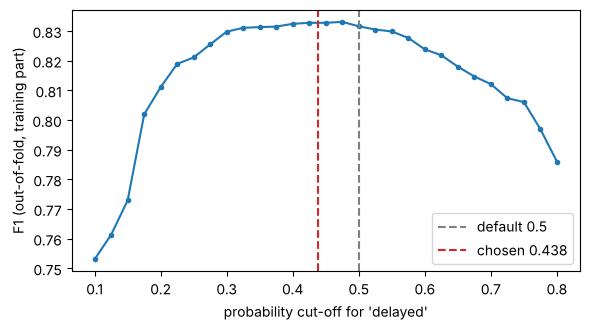

In [10]:
oof = cross_val_predict(tree, X_train, y_train, cv=CV5, method="predict_proba")[:, 1]
grid = np.round(np.arange(0.10, 0.801, 0.025), 3)
f1_curve = np.array([f1_score(y_train, oof >= t) for t in grid])
# pick the middle of the near-best plateau rather than a single noisy peak
good = grid[f1_curve >= f1_curve.max() - 0.001]
THRESHOLD = float(np.round(np.median(good), 3))
print(f"Chosen cut-off: {THRESHOLD}   (out-of-fold F1 {f1_score(y_train, oof >= THRESHOLD):.4f}; the single best cut-off in the grid was {grid[f1_curve.argmax()]} with {f1_curve.max():.4f})")

plt.figure(figsize=(6, 3.4))
plt.plot(grid, f1_curve, marker="o", ms=3); plt.axvline(0.5, color="grey", ls="--", label="default 0.5")
plt.axvline(THRESHOLD, color="C3", ls="--", label=f"chosen {THRESHOLD}")
plt.xlabel("probability cut-off for 'delayed'"); plt.ylabel("F1 (out-of-fold, training part)"); plt.legend(); plt.tight_layout(); plt.show()

**Hold-out and over-fitting check.**

Now the 20% hold-out flights are used for the first time. Three F1 scores are compared at the chosen cut-off:

* **in-sample**: the tree scored on the very flights it was trained on (always the most flattering)
* **cross-validated**: out-of-fold predictions on the training part
* **hold-out**: flights the tree has never seen

If in-sample were far above the other two, the tree would be over-trained. If cross-validated and hold-out agree, the estimate can be trusted.

,accuracy,precision,recall,F1,AUC
Always predict 'not delayed' (hold-out),0.6717,0.0000,0.0000,0.0000,0.5000
"IN-SAMPLE, cut-off 0.438",0.9047,0.8833,0.8176,0.8492,0.9465
"CROSS-VALIDATED, cut-off 0.438",0.8935,0.8578,0.8098,0.8331,0.9400
"HOLD-OUT, cut-off 0.438",0.8935,0.8580,0.8096,0.8331,0.9398


In-sample minus hold-out F1: +0.0161   |   cross-validated minus hold-out F1: +0.0000
A small in-sample gap (a few points) is normal for any tree. What matters is that cross-validated and hold-out agree to within about 1 point, which means the tree's skill is real and not memorised.
Rough size of the sampling error on 8,500 flights: about +/- 1 percentage point. Do not tweak settings to push the hold-out number up.


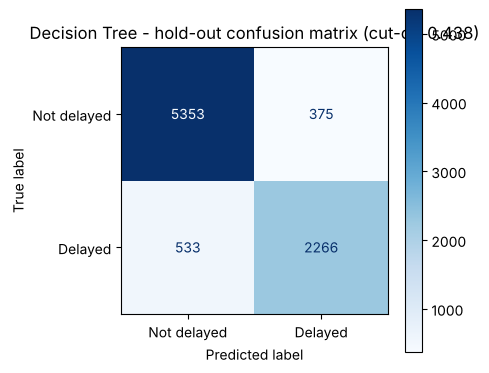

In [11]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
s = tree.predict_proba(X_test)[:, 1]; s_train = tree.predict_proba(X_train)[:, 1]
def row(y, pred, score):
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred), F1=f1_score(y, pred), AUC=roc_auc_score(y, score))
res = pd.DataFrame([dict(accuracy=accuracy_score(y_test, dummy.predict(X_test)), precision=0.0, recall=0.0, F1=0.0, AUC=0.5),
                    row(y_train, (s_train >= THRESHOLD).astype(int), s_train),
                    row(y_train, (oof >= THRESHOLD).astype(int), oof),
                    row(y_test, (s >= THRESHOLD).astype(int), s)],
                   index=["Always predict 'not delayed' (hold-out)", f"IN-SAMPLE, cut-off {THRESHOLD}", f"CROSS-VALIDATED, cut-off {THRESHOLD}", f"HOLD-OUT, cut-off {THRESHOLD}"])
display(res.round(4))
gap = res.iloc[1].F1 - res.iloc[3].F1
print(f"In-sample minus hold-out F1: {gap:+.4f}   |   cross-validated minus hold-out F1: {res.iloc[2].F1 - res.iloc[3].F1:+.4f}")
print("A small in-sample gap (a few points) is normal for any tree. What matters is that cross-validated and hold-out agree to within about 1 point, which means the tree's skill is real and not memorised.")
print("Rough size of the sampling error on 8,500 flights: about +/- 1 percentage point. Do not tweak settings to push the hold-out number up.")

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, (s >= THRESHOLD).astype(int), display_labels=["Not delayed", "Delayed"], cmap="Blues", ax=ax)
ax.set_title(f"Decision Tree - hold-out confusion matrix (cut-off {THRESHOLD})"); plt.tight_layout(); plt.show()

h = lambda p: res[res.index.str.startswith(p)].F1.iloc[0]
MODELS["Decision Tree"] = dict(tree=tree, threshold=THRESHOLD)
RESULTS["Decision Tree"] = {"CV F1": h("CROSS-VALIDATED"), "hold-out F1": h("HOLD-OUT"), "in-sample F1": h("IN-SAMPLE"),
                            "cut-off": THRESHOLD, "flagged": (oof >= THRESHOLD).mean(), "search F1": search.best_score_}

In [12]:
# what does a shallow version of the tree say? (depth 3, easy to read; the tuned tree itself is far larger)
small = make_pipe(DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE), "full", False).fit(X_train, y_train)
print(export_text(small.named_steps["clf"], feature_names=list(small.named_steps["pre"].get_feature_names_out()), max_depth=3, show_weights=True))
print("depth-3 tree hold-out accuracy:", round(accuracy_score(y_test, small.predict(X_test)), 4))

|--- num__ARR_IF_LATE <= 7.75
|   |--- num__PDELAY_UB <= 26.50
|   |   |--- num__TOTAL_DELAY_EST <= 1.25
|   |   |   |--- weights: [15716.00, 753.00] class: 0
|   |   |--- num__TOTAL_DELAY_EST >  1.25
|   |   |   |--- weights: [1279.00, 398.00] class: 0
|   |--- num__PDELAY_UB >  26.50
|   |   |--- num__TOTAL_DELAY_EST <= -5.53
|   |   |   |--- weights: [3058.00, 504.00] class: 0
|   |   |--- num__TOTAL_DELAY_EST >  -5.53
|   |   |   |--- weights: [1670.00, 928.00] class: 0
|--- num__ARR_IF_LATE >  7.75
|   |--- num__PTOTAL_DELAY_EST <= 9.75
|   |   |--- num__TOTAL_DELAY_EST <= 6.75
|   |   |   |--- weights: [483.00, 564.00] class: 1
|   |   |--- num__TOTAL_DELAY_EST >  6.75
|   |   |   |--- weights: [271.00, 797.00] class: 1
|   |--- num__PTOTAL_DELAY_EST >  9.75
|   |   |--- num__D_NEXT_DEP <= 5.50
|   |   |   |--- weights: [399.00, 3263.00] class: 1
|   |   |--- num__D_NEXT_DEP >  5.50
|   |   |   |--- weights: [33.00, 3991.00] class: 1

depth-3 tree hold-out accuracy: 0.8902


### 5.2 KNN

**K-Nearest Neighbours** classifies a flight by looking at the *k* most similar training flights (closest in feature space) and letting them vote. It has no training step, so everything depends on the features and on the distance, which is why the inputs are **standardised** (otherwise minutes and miles would dominate). Feature set: with slot columns.

**Tuning.**

* `n_neighbors` (k): how many neighbours vote (small = jagged, large = smooth)
* `weights`: `uniform` (equal votes) or `distance` (closer neighbours count more)
* `p`: distance type (1 = Manhattan, 2 = Euclidean)
* `pre`: which **feature set** to use (`full`, `compact` = raw columns plus schedule gap, `compact+date` = compact plus the date encoding). Distance methods suffer when many weak features are included, so this is tuned too.

A randomised search tries 20 combinations, each scored by **3-fold stratified cross-validation inside the 80% training part**, using the **best F1 over a range of cut-offs** (the cut-off is chosen afterwards).

In [13]:
use_features("slots")
CV = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

base = make_pipe(KNeighborsClassifier(), "compact", True)
space = {"pre": PRE_SCALED, "clf__n_neighbors": [5, 11, 21, 31, 51, 75, 101], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}
t0 = time.time()
search = RandomizedSearchCV(base, space, n_iter=20, cv=CV, scoring=best_cutoff_f1, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
tree = search.best_estimator_  # (the fitted, tuned model)

print(f"Done in {time.time() - t0:.0f}s")
print("Best settings:", {k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in search.best_params_.items()})
print(f"Cross-validated F1 (best cut-off) on the training part: {search.best_score_:.4f} (+/- {search.cv_results_['std_test_score'][search.best_index_]:.4f} between folds)")
r = pd.DataFrame(search.cv_results_)
r["settings"] = [str({k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in p.items()}) for p in r.params]
print(f"\nTop 6 of the {len(r)} settings tried:")
print(r.sort_values("mean_test_score", ascending=False)[["mean_test_score", "std_test_score", "settings"]].head(6).round(4).to_string(index=False, max_colwidth=130))

Done in 127s
Best settings: {'pre': 'compact+date', 'weights': 'distance', 'p': 1, 'n_neighbors': 75}
Cross-validated F1 (best cut-off) on the training part: 0.8254 (+/- 0.0025 between folds)

Top 6 of the 20 settings tried:
 mean_test_score  std_test_score                                                                  settings
          0.8254          0.0025 {'pre': 'compact+date', 'weights': 'distance', 'p': 1, 'n_neighbors': 75}
          0.8246          0.0039     {'pre': 'compact', 'weights': 'distance', 'p': 1, 'n_neighbors': 101}
          0.8239          0.0034      {'pre': 'compact', 'weights': 'uniform', 'p': 1, 'n_neighbors': 101}
          0.8179          0.0034       {'pre': 'compact', 'weights': 'uniform', 'p': 1, 'n_neighbors': 51}
          0.8158          0.0014      {'pre': 'compact', 'weights': 'distance', 'p': 1, 'n_neighbors': 31}
          0.7932          0.0015      {'pre': 'compact', 'weights': 'distance', 'p': 2, 'n_neighbors': 75}


Chosen cut-off: 0.2677  -> flags 32.5% of flights as delayed; out-of-fold F1 0.8248


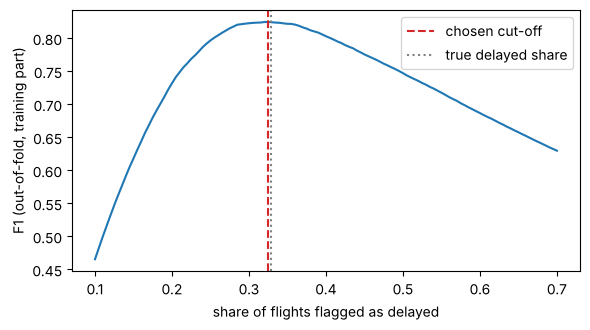

,accuracy,precision,recall,F1,AUC
Always predict 'not delayed' (hold-out),0.6717,0.0000,0.0000,0.0000,0.5000
Model's default rule (hold-out),0.8590,0.9689,0.5895,0.7330,0.9461
"IN-SAMPLE, chosen cut-off",0.9942,0.9836,0.9990,0.9912,0.9999
"CROSS-VALIDATED, chosen cut-off",0.8855,0.8290,0.8206,0.8248,0.9448
"HOLD-OUT, chosen cut-off",0.8847,0.8238,0.8253,0.8246,0.9461


In-sample minus hold-out F1: +0.1667   |   cross-validated minus hold-out F1: +0.0002
What matters is that cross-validated and hold-out agree to within about 1 point: then the skill is real and not memorised.
Rough size of the sampling error on 8,500 flights: about +/- 1 percentage point. Do not tweak settings to push the hold-out number up.


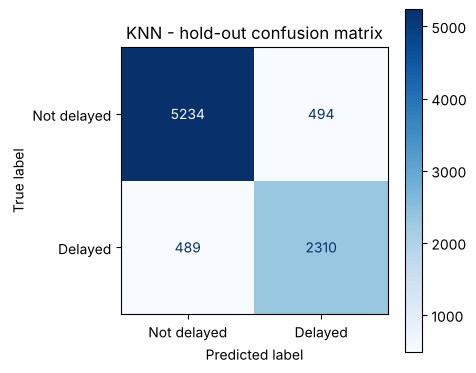

In [14]:
oof, THRESHOLD, share = choose_cutoff(tree, CV)
res = holdout_check("KNN", tree, oof, THRESHOLD)
record("KNN", search, tree, oof, THRESHOLD, share, res)

### 5.3 Random Forest

A **Random Forest** grows many decision trees, each on a random resample of the flights and a random subset of features at every split, and averages their votes. Averaging cancels out the over-fitting of individual trees. No scaling is needed. Feature set: without slot columns.

**Tuning.**

* `n_estimators`: number of trees (more = steadier, slower)
* `max_depth`, `min_samples_leaf`: how big each tree may grow (limits over-fitting)
* `max_features`: how many features each split may look at (`sqrt` or a fraction)
* `class_weight`: `balanced_subsample` makes delayed flights count more, which suits F1

A randomised search tries 15 combinations, each scored by **3-fold stratified cross-validation inside the 80% training part**, using the **best F1 over a range of cut-offs**.

In [15]:
use_features("pooled")
CV = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

base = make_pipe(RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE), "full", False)
space = {"clf__n_estimators": [200, 400], "clf__max_depth": [8, 12, 16, None], "clf__min_samples_leaf": [1, 3, 5, 10, 20],
         "clf__max_features": ["sqrt", 0.3, 0.5], "clf__class_weight": [None, "balanced_subsample"]}
t0 = time.time()
search = RandomizedSearchCV(base, space, n_iter=15, cv=CV, scoring=best_cutoff_f1, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
tree = search.best_estimator_

print(f"Done in {time.time() - t0:.0f}s")
print("Best settings:", {k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in search.best_params_.items()})
print(f"Cross-validated F1 (best cut-off) on the training part: {search.best_score_:.4f} (+/- {search.cv_results_['std_test_score'][search.best_index_]:.4f} between folds)")
r = pd.DataFrame(search.cv_results_)
r["settings"] = [str({k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in p.items()}) for p in r.params]
print(f"\nTop 6 of the {len(r)} settings tried:")
print(r.sort_values("mean_test_score", ascending=False)[["mean_test_score", "std_test_score", "settings"]].head(6).round(4).to_string(index=False, max_colwidth=130))

Done in 842s
Best settings: {'n_estimators': 400, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': None}
Cross-validated F1 (best cut-off) on the training part: 0.8473 (+/- 0.0023 between folds)

Top 6 of the 15 settings tried:
 mean_test_score  std_test_score                                                                                                                  settings
          0.8473          0.0023             {'n_estimators': 400, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': None}
          0.8467          0.0019                  {'n_estimators': 400, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 12, 'class_weight': None}
          0.8465          0.0013 {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 16, 'class_weight': 'balanced_subsample'}
          0.8458          0.0014  {'n_estimators': 200, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': 12, 'c

Chosen cut-off: 0.4361  -> flags 30.8% of flights as delayed; out-of-fold F1 0.8453


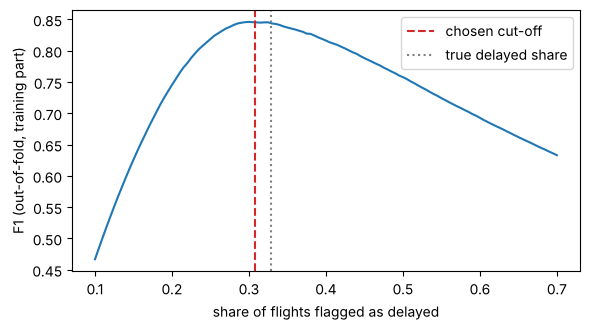

,accuracy,precision,recall,F1,AUC
Always predict 'not delayed' (hold-out),0.6717,0.0000,0.0000,0.0000,0.5000
Model's default rule (hold-out),0.9031,0.8976,0.7956,0.8436,0.9574
"IN-SAMPLE, chosen cut-off",0.9745,0.9694,0.9523,0.9608,0.9980
"CROSS-VALIDATED, chosen cut-off",0.9016,0.8737,0.8186,0.8453,0.9565
"HOLD-OUT, chosen cut-off",0.9031,0.8735,0.8242,0.8482,0.9574


In-sample minus hold-out F1: +0.1126   |   cross-validated minus hold-out F1: -0.0029
What matters is that cross-validated and hold-out agree to within about 1 point: then the skill is real and not memorised.
Rough size of the sampling error on 8,500 flights: about +/- 1 percentage point. Do not tweak settings to push the hold-out number up.


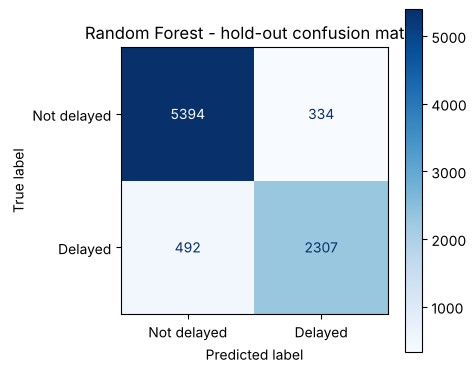

In [16]:
oof, THRESHOLD, share = choose_cutoff(tree, CV)
res = holdout_check("Random Forest", tree, oof, THRESHOLD)
record("Random Forest", search, tree, oof, THRESHOLD, share, res)

### 5.4 SVM

A **Support Vector Machine (RBF kernel)** finds the boundary that separates delayed from on-time flights with the widest possible margin, after bending the feature space with a radial-basis kernel so the boundary can be curved. Inputs are **standardised**. The model outputs a signed distance from the boundary rather than a probability, and the cut-off is applied to that distance. Feature set: without slot columns.

**Tuning.**

* `C`: how strongly mistakes are punished (high = fits the training data tightly, risk of over-fitting)
* `gamma`: how local the curved boundary is (high = wiggly, low = smooth)
* `class_weight`: `balanced` makes delayed flights count more, which suits F1
* `pre`: which feature set to use (`full`, `compact`, `compact+date`)

SVM training time grows roughly with the square of the number of rows, so the search runs on a **stratified subsample of 8,000 training flights**; the winning settings are then **re-fitted on the whole 80% training part**. 12 combinations are tried, each scored by **3-fold cross-validation**, using the **best F1 over a range of cut-offs**.

In [17]:
use_features("pooled")
CV = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

base = make_pipe(SVC(kernel="rbf", cache_size=1000, random_state=RANDOM_STATE), "compact", True)
space = {"pre": PRE_SCALED, "clf__C": [0.5, 1, 2, 5, 10], "clf__gamma": ["scale", 0.01, 0.03, 0.1], "clf__class_weight": [None, "balanced"]}
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=8000, stratify=y_train, random_state=RANDOM_STATE)
t0 = time.time()
search = RandomizedSearchCV(base, space, n_iter=12, cv=CV, scoring=best_cutoff_f1, n_jobs=-1, random_state=RANDOM_STATE).fit(X_sub, y_sub)
tree = clone(base).set_params(**search.best_params_).fit(X_train, y_train)   # re-fit the winner on the full training part
print("(tuned on an 8,000-flight subsample, re-fitted on all", len(X_train), "training flights)")

print(f"Done in {time.time() - t0:.0f}s")
print("Best settings:", {k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in search.best_params_.items()})
print(f"Cross-validated F1 (best cut-off) on the training part: {search.best_score_:.4f} (+/- {search.cv_results_['std_test_score'][search.best_index_]:.4f} between folds)")
r = pd.DataFrame(search.cv_results_)
r["settings"] = [str({k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in p.items()}) for p in r.params]
print(f"\nTop 6 of the {len(r)} settings tried:")
print(r.sort_values("mean_test_score", ascending=False)[["mean_test_score", "std_test_score", "settings"]].head(6).round(4).to_string(index=False, max_colwidth=130))

(tuned on an 8,000-flight subsample, re-fitted on all 34107 training flights)
Done in 44s
Best settings: {'pre': 'compact+date', 'gamma': 0.03, 'class_weight': 'balanced', 'C': 1}
Cross-validated F1 (best cut-off) on the training part: 0.8366 (+/- 0.0063 between folds)

Top 6 of the 12 settings tried:
 mean_test_score  std_test_score                                                                      settings
          0.8366          0.0063    {'pre': 'compact+date', 'gamma': 0.03, 'class_weight': 'balanced', 'C': 1}
          0.8363          0.0038       {'pre': 'compact+date', 'gamma': 'scale', 'class_weight': None, 'C': 1}
          0.8363          0.0050 {'pre': 'compact+date', 'gamma': 'scale', 'class_weight': 'balanced', 'C': 2}
          0.8343          0.0048               {'pre': 'compact', 'gamma': 0.03, 'class_weight': None, 'C': 2}
          0.8335          0.0029            {'pre': 'compact', 'gamma': 'scale', 'class_weight': None, 'C': 5}
          0.8298          0.007

Chosen cut-off: 0.2335  -> flags 31.5% of flights as delayed; out-of-fold F1 0.8399


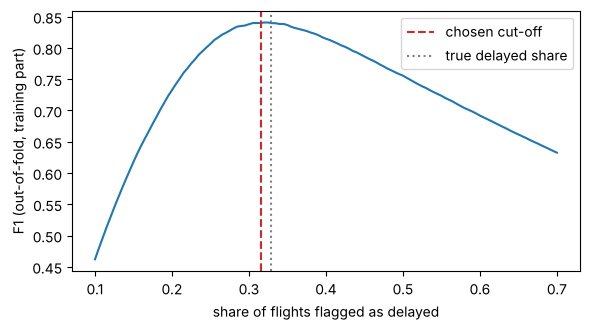

,accuracy,precision,recall,F1,AUC
Always predict 'not delayed' (hold-out),0.6717,0.0000,0.0000,0.0000,0.5000
Model's default rule (hold-out),0.8884,0.8106,0.8610,0.8351,0.9542
"IN-SAMPLE, chosen cut-off",0.9082,0.8721,0.8443,0.8579,0.9609
"CROSS-VALIDATED, chosen cut-off",0.8970,0.8576,0.8228,0.8399,0.9527
"HOLD-OUT, chosen cut-off",0.8947,0.8493,0.8257,0.8373,0.9542


In-sample minus hold-out F1: +0.0206   |   cross-validated minus hold-out F1: +0.0025
What matters is that cross-validated and hold-out agree to within about 1 point: then the skill is real and not memorised.
Rough size of the sampling error on 8,500 flights: about +/- 1 percentage point. Do not tweak settings to push the hold-out number up.


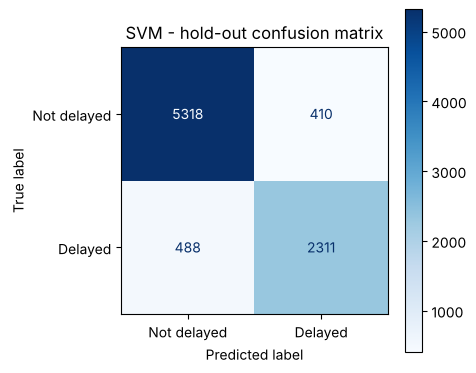

In [18]:
oof, THRESHOLD, share = choose_cutoff(tree, CV)
res = holdout_check("SVM", tree, oof, THRESHOLD)
record("SVM", search, tree, oof, THRESHOLD, share, res)

### 5.5 Neural Network

A **neural network (multi-layer perceptron)** passes the standardised features through one or more layers of weighted sums and non-linear units, and learns the weights by gradient descent. Training stops early when a held-out slice of the training rows stops improving, which guards against over-fitting. Feature set: without slot columns.

**Tuning.**

* `hidden_layer_sizes`: the shape of the network, e.g. `(64, 32)` = two layers of 64 and 32 units
* `alpha`: L2 penalty on the weights (bigger = simpler network, less over-fitting)
* `learning_rate_init`: starting step size of the optimiser

`early_stopping=True` is fixed. A randomised search tries 10 combinations, each scored by **3-fold stratified cross-validation inside the 80% training part**, using the **best F1 over a range of cut-offs**.

In [19]:
use_features("pooled")
CV = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

base = make_pipe(MLPClassifier(max_iter=300, early_stopping=True, n_iter_no_change=10, random_state=RANDOM_STATE), "full", True)
space = {"clf__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)], "clf__alpha": [1e-5, 1e-4, 1e-3, 1e-2], "clf__learning_rate_init": [1e-3, 3e-3]}
t0 = time.time()
search = RandomizedSearchCV(base, space, n_iter=10, cv=CV, scoring=best_cutoff_f1, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
tree = search.best_estimator_

print(f"Done in {time.time() - t0:.0f}s")
print("Best settings:", {k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in search.best_params_.items()})
print(f"Cross-validated F1 (best cut-off) on the training part: {search.best_score_:.4f} (+/- {search.cv_results_['std_test_score'][search.best_index_]:.4f} between folds)")
r = pd.DataFrame(search.cv_results_)
r["settings"] = [str({k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in p.items()}) for p in r.params]
print(f"\nTop 6 of the {len(r)} settings tried:")
print(r.sort_values("mean_test_score", ascending=False)[["mean_test_score", "std_test_score", "settings"]].head(6).round(4).to_string(index=False, max_colwidth=130))

Done in 36s
Best settings: {'learning_rate_init': 0.001, 'hidden_layer_sizes': (64, 32), 'alpha': 0.0001}
Cross-validated F1 (best cut-off) on the training part: 0.8422 (+/- 0.0047 between folds)

Top 6 of the 10 settings tried:
 mean_test_score  std_test_score                                                                       settings
          0.8422          0.0047 {'learning_rate_init': 0.001, 'hidden_layer_sizes': (64, 32), 'alpha': 0.0001}
          0.8413          0.0038     {'learning_rate_init': 0.001, 'hidden_layer_sizes': (32,), 'alpha': 1e-05}
          0.8409          0.0051  {'learning_rate_init': 0.001, 'hidden_layer_sizes': (128, 64), 'alpha': 0.01}
          0.8407          0.0035      {'learning_rate_init': 0.001, 'hidden_layer_sizes': (32,), 'alpha': 0.01}
          0.8407          0.0032    {'learning_rate_init': 0.001, 'hidden_layer_sizes': (32,), 'alpha': 0.0001}
          0.8405          0.0035    {'learning_rate_init': 0.003, 'hidden_layer_sizes': (32,), 'alp

Chosen cut-off: 0.4655  -> flags 31.5% of flights as delayed; out-of-fold F1 0.8418


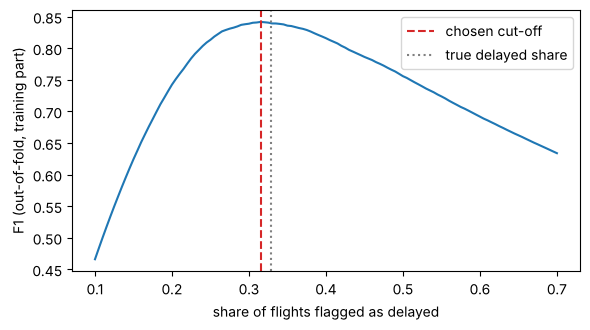

,accuracy,precision,recall,F1,AUC
Always predict 'not delayed' (hold-out),0.6717,0.0000,0.0000,0.0000,0.5000
Model's default rule (hold-out),0.8979,0.8731,0.8060,0.8382,0.9556
"IN-SAMPLE, chosen cut-off",0.9134,0.8904,0.8394,0.8642,0.9663
"CROSS-VALIDATED, chosen cut-off",0.8982,0.8595,0.8247,0.8418,0.9549
"HOLD-OUT, chosen cut-off",0.8974,0.8630,0.8171,0.8394,0.9556


In-sample minus hold-out F1: +0.0247   |   cross-validated minus hold-out F1: +0.0023
What matters is that cross-validated and hold-out agree to within about 1 point: then the skill is real and not memorised.
Rough size of the sampling error on 8,500 flights: about +/- 1 percentage point. Do not tweak settings to push the hold-out number up.


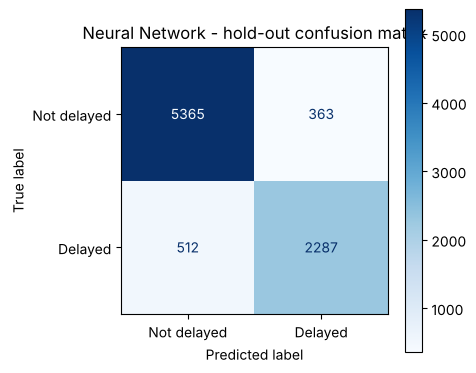

In [20]:
oof, THRESHOLD, share = choose_cutoff(tree, CV)
res = holdout_check("Neural Network", tree, oof, THRESHOLD)
record("Neural Network", search, tree, oof, THRESHOLD, share, res)

### 5.6 Logistic Regression

**Logistic regression** (an *extra* model, not in the lecture list) is a linear model: it adds up weighted features and squashes the total into a probability. It is simple, fast and easy to interpret, which makes it a useful baseline against the more flexible models. Inputs are **standardised**. Feature set: without slot columns.

**Tuning.**

* `C`: inverse regularisation strength (small = heavily simplified, large = fits tightly)
* `class_weight`: `balanced` makes delayed flights count more, which suits F1
* `pre`: which feature set to use (`full` or `compact+date`)

A randomised search tries 12 combinations, each scored by **5-fold stratified cross-validation inside the 80% training part**, using the **best F1 over a range of cut-offs**.

In [21]:
use_features("pooled")
CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

base = make_pipe(LogisticRegression(max_iter=3000), "full", True)
space = {"pre": [make_pre("full", True), make_pre("compact+date", True)], "clf__C": [0.01, 0.03, 0.1, 1, 10, 100], "clf__class_weight": [None, "balanced"]}
t0 = time.time()
search = RandomizedSearchCV(base, space, n_iter=12, cv=CV, scoring=best_cutoff_f1, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
tree = search.best_estimator_

print(f"Done in {time.time() - t0:.0f}s")
print("Best settings:", {k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in search.best_params_.items()})
print(f"Cross-validated F1 (best cut-off) on the training part: {search.best_score_:.4f} (+/- {search.cv_results_['std_test_score'][search.best_index_]:.4f} between folds)")
r = pd.DataFrame(search.cv_results_)
r["settings"] = [str({k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in p.items()}) for p in r.params]
print(f"\nTop 6 of the {len(r)} settings tried:")
print(r.sort_values("mean_test_score", ascending=False)[["mean_test_score", "std_test_score", "settings"]].head(6).round(4).to_string(index=False, max_colwidth=130))

Done in 18s
Best settings: {'pre': 'compact+date', 'class_weight': 'balanced', 'C': 0.1}
Cross-validated F1 (best cut-off) on the training part: 0.7847 (+/- 0.0053 between folds)

Top 6 of the 12 settings tried:
 mean_test_score  std_test_score                                                      settings
          0.7847          0.0053 {'pre': 'compact+date', 'class_weight': 'balanced', 'C': 0.1}
          0.7817          0.0078          {'pre': 'full', 'class_weight': 'balanced', 'C': 10}
          0.7809          0.0074        {'pre': 'full', 'class_weight': 'balanced', 'C': 0.01}
          0.7727          0.0071                 {'pre': 'full', 'class_weight': None, 'C': 1}
          0.7723          0.0076                {'pre': 'full', 'class_weight': None, 'C': 10}
          0.7720          0.0087               {'pre': 'full', 'class_weight': None, 'C': 0.1}


Chosen cut-off: 0.5596  -> flags 32.7% of flights as delayed; out-of-fold F1 0.7829


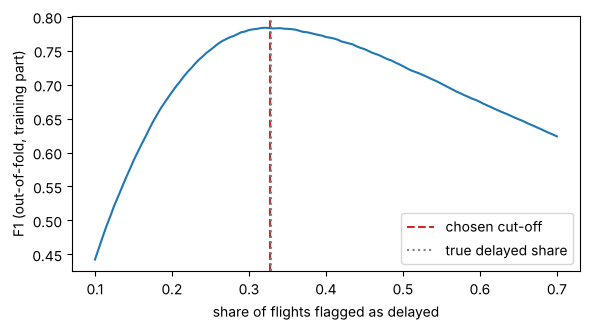

,accuracy,precision,recall,F1,AUC
Always predict 'not delayed' (hold-out),0.6717,0.0000,0.0000,0.0000,0.5000
Model's default rule (hold-out),0.8515,0.7461,0.8303,0.7859,0.9167
"IN-SAMPLE, chosen cut-off",0.8605,0.7876,0.7876,0.7876,0.9195
"CROSS-VALIDATED, chosen cut-off",0.8577,0.7842,0.7816,0.7829,0.9163
"HOLD-OUT, chosen cut-off",0.8609,0.7865,0.7910,0.7887,0.9167


In-sample minus hold-out F1: -0.0012   |   cross-validated minus hold-out F1: -0.0059
What matters is that cross-validated and hold-out agree to within about 1 point: then the skill is real and not memorised.
Rough size of the sampling error on 8,500 flights: about +/- 1 percentage point. Do not tweak settings to push the hold-out number up.


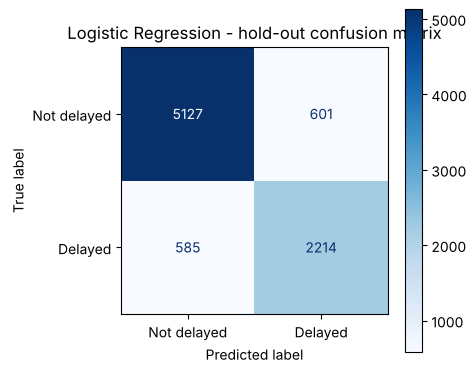

In [22]:
oof, THRESHOLD, share = choose_cutoff(tree, CV)
res = holdout_check("Logistic Regression", tree, oof, THRESHOLD)
record("Logistic Regression", search, tree, oof, THRESHOLD, share, res)

### 5.7 Gradient Boosting

**Gradient boosting** (an *extra* model, not in the lecture list) builds small decision trees one after another, each one correcting the mistakes of the trees before it. It is usually the strongest model on tabular data like this. scikit-learn's histogram version (`HistGradientBoostingClassifier`) is used. No scaling is needed, and training stops early when a held-out slice stops improving. Feature set: with slot columns.

**Tuning.**

* `learning_rate`: how much each new tree contributes (small = slower, steadier)
* `max_leaf_nodes`, `min_samples_leaf`: size limits for each tree (guard against over-fitting)
* `l2_regularization`: penalty on large leaf values
* `class_weight`: `balanced` makes delayed flights count more, which suits F1

`early_stopping=True` is fixed. A randomised search tries 15 combinations, each scored by **5-fold stratified cross-validation inside the 80% training part**, using the **best F1 over a range of cut-offs**.

In [23]:
use_features("slots")
CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

base = make_pipe(HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.1, n_iter_no_change=50, max_iter=3000, random_state=RANDOM_STATE), "full", False)
space = {"clf__learning_rate": [0.02, 0.03, 0.05, 0.1], "clf__max_leaf_nodes": [15, 31, 63], "clf__min_samples_leaf": [20, 30, 50, 100],
         "clf__l2_regularization": [0, 1, 10], "clf__class_weight": [None, "balanced"]}
t0 = time.time()
search = RandomizedSearchCV(base, space, n_iter=15, cv=CV, scoring=best_cutoff_f1, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
tree = search.best_estimator_

print(f"Done in {time.time() - t0:.0f}s")
print("Best settings:", {k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in search.best_params_.items()})
print(f"Cross-validated F1 (best cut-off) on the training part: {search.best_score_:.4f} (+/- {search.cv_results_['std_test_score'][search.best_index_]:.4f} between folds)")
r = pd.DataFrame(search.cv_results_)
r["settings"] = [str({k.replace("clf__", ""): (fset_label(v) if k == "pre" else v) for k, v in p.items()}) for p in r.params]
print(f"\nTop 6 of the {len(r)} settings tried:")
print(r.sort_values("mean_test_score", ascending=False)[["mean_test_score", "std_test_score", "settings"]].head(6).round(4).to_string(index=False, max_colwidth=130))

Done in 237s
Best settings: {'min_samples_leaf': 30, 'max_leaf_nodes': 31, 'learning_rate': 0.05, 'l2_regularization': 1, 'class_weight': None}
Cross-validated F1 (best cut-off) on the training part: 0.8548 (+/- 0.0045 between folds)

Top 6 of the 15 settings tried:
 mean_test_score  std_test_score                                                                                                                   settings
          0.8548          0.0045        {'min_samples_leaf': 30, 'max_leaf_nodes': 31, 'learning_rate': 0.05, 'l2_regularization': 1, 'class_weight': None}
          0.8541          0.0033 {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'learning_rate': 0.02, 'l2_regularization': 1, 'class_weight': 'balanced'}
          0.8540          0.0035  {'min_samples_leaf': 30, 'max_leaf_nodes': 15, 'learning_rate': 0.03, 'l2_regularization': 0, 'class_weight': 'balanced'}
          0.8538          0.0033 {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'learning_rate': 0.1, 'l2_re

Chosen cut-off: 0.4201  -> flags 31.8% of flights as delayed; out-of-fold F1 0.8534


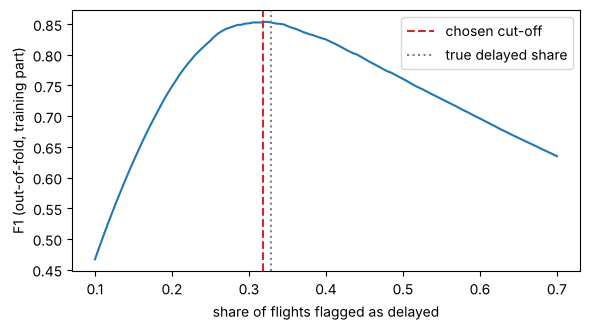

,accuracy,precision,recall,F1,AUC
Always predict 'not delayed' (hold-out),0.6717,0.0000,0.0000,0.0000,0.5000
Model's default rule (hold-out),0.9074,0.8862,0.8235,0.8537,0.9616
"IN-SAMPLE, chosen cut-off",0.9380,0.9162,0.8927,0.9043,0.9829
"CROSS-VALIDATED, chosen cut-off",0.9053,0.8677,0.8396,0.8534,0.9610
"HOLD-OUT, chosen cut-off",0.9044,0.8599,0.8467,0.8533,0.9616


In-sample minus hold-out F1: +0.0510   |   cross-validated minus hold-out F1: +0.0002
What matters is that cross-validated and hold-out agree to within about 1 point: then the skill is real and not memorised.
Rough size of the sampling error on 8,500 flights: about +/- 1 percentage point. Do not tweak settings to push the hold-out number up.


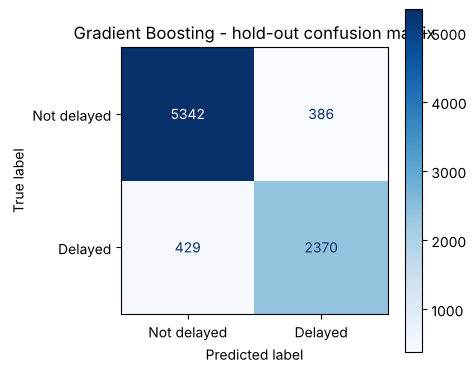

In [24]:
oof, THRESHOLD, share = choose_cutoff(tree, CV)
res = holdout_check("Gradient Boosting", tree, oof, THRESHOLD)
record("Gradient Boosting", search, tree, oof, THRESHOLD, share, res)

## 6. Comparison of the seven models

All seven models use the same 80/20 split. *CV F1* is the out-of-fold F1 on the training part at the chosen cut-off, *hold-out F1* is the F1 on the 20% of flights no model has seen, and *Kaggle* is the public leaderboard score (typed in by hand from the Kaggle page after each submission). The Kaggle score is **not** used to choose settings.

,CV F1,hold-out F1,in-sample F1,cut-off,flagged,Kaggle
Gradient Boosting,0.8534,0.8533,0.9043,0.4201,0.3177,0.8471
Random Forest,0.8453,0.8482,0.9608,0.4361,0.3076,0.8396
SVM,0.8399,0.8373,0.8579,0.2335,0.3150,0.8391
Neural Network,0.8418,0.8394,0.8642,0.4655,0.3150,0.8362
Decision Tree,0.8331,0.8331,0.8492,0.4380,0.3099,0.8275
KNN,0.8248,0.8246,0.9912,0.2677,0.3250,0.8168
Logistic Regression,0.7829,0.7887,0.7876,0.5596,0.3272,0.7730


Highest cross-validated F1: Gradient Boosting | highest hold-out F1: Gradient Boosting | highest Kaggle score: Gradient Boosting


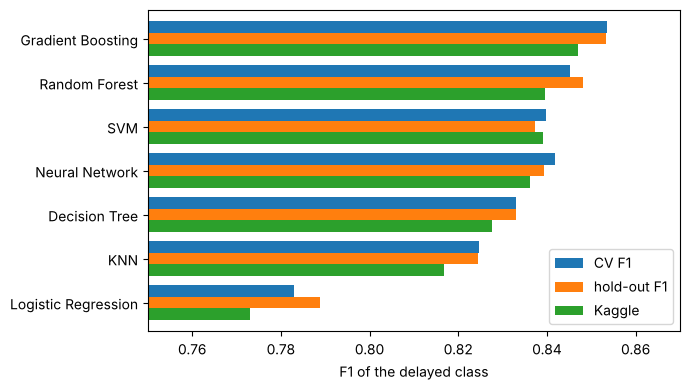

In [25]:
KAGGLE = {"Gradient Boosting": 0.8471, "Random Forest": 0.8396, "SVM": 0.8391, "Neural Network": 0.8362,
          "Decision Tree": 0.8275, "KNN": 0.8168, "Logistic Regression": 0.7730}      # public leaderboard scores, entered by hand
summary = pd.DataFrame(RESULTS).T[["CV F1", "hold-out F1", "in-sample F1", "cut-off", "flagged"]]
summary["Kaggle"] = pd.Series(KAGGLE)
summary = summary.loc[list(KAGGLE)]
display(summary.round(4))
best = summary["hold-out F1"].idxmax()
print(f"Highest cross-validated F1: {summary['CV F1'].idxmax()} | highest hold-out F1: {best} | highest Kaggle score: {summary['Kaggle'].astype(float).idxmax()}")

ax = summary[["CV F1", "hold-out F1", "Kaggle"]].astype(float).plot.barh(figsize=(7, 4), width=0.8)
ax.set_xlim(0.75, 0.87); ax.invert_yaxis(); ax.set_xlabel("F1 of the delayed class"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 7. Write the Kaggle files

Every model is turned into a Kaggle file the same way: its tuned settings are **re-fitted on all labelled flights** (the 80% and the 20% together), because more data helps and the checks above are done; the model scores each Unknown flight; and the model's own chosen cut-off turns the score into 0/1. Each file is checked against the sample before it is saved: same column names, same row IDs in the same order, 0/1 integers only.

* **7.1** prepares the Unknown file and defines the writer, then saves the files of the six other models in the folder `other_models/` (these are the files that were submitted to Kaggle for the scores in section 6).
* **7.2** saves the file of the selected model, Gradient Boosting, as **`gb_predictions.csv`**. It has the highest cross-validated F1, the highest hold-out F1 and the highest Kaggle score, so this is the file for the assignment.

### 7.1 The six other models

In [26]:
# --- read and prepare the Unknown file (same columns as the labelled file, no answers) ---
sample = pd.read_csv(SAMPLE_PATH)
X_unk = unk_raw.copy()
missing_cols = [c for c in FEATURE_COLS if c not in X_unk.columns]
assert not missing_cols, f"Unknown dataset is missing columns: {missing_cols}"
X_unk = X_unk[FEATURE_COLS].copy()
X_unk["DATE"], unk_sorted = fill_dates_by_order(X_unk["DATE"])
print(f"Unknown set: {X_unk.shape} | date-sorted: {unk_sorted} | dates still missing: {int(X_unk.DATE.isna().sum())}")
assert len(X_unk) == len(sample), f"Unknown file has {len(X_unk)} rows but the sample has {len(sample)}"

def write_kaggle(name, path):
    """Re-fit the tuned model on ALL labelled flights, score the Unknown flights, apply the model's cut-off, check the format, save."""
    t0 = time.time()
    tree, THRESHOLD = MODELS[name]["tree"], MODELS[name]["threshold"]
    final = clone(tree)
    if "clf__n_jobs" in final.get_params(): final.set_params(clf__n_jobs=-1)
    final.fit(X_all, y_all)
    pred = (scores_of(final, X_unk) >= THRESHOLD).astype(int)
    sub = pd.DataFrame({"row ID": sample.iloc[:, 0].values, "Predicted_Arrival_Delay": pred})
    assert list(sub.columns) == list(sample.columns), f"columns {list(sub.columns)} != {list(sample.columns)}"
    assert len(sub) == len(sample) and (sub.iloc[:, 0].values == sample.iloc[:, 0].values).all()
    assert set(sub["Predicted_Arrival_Delay"].unique()) <= {0, 1} and sub["Predicted_Arrival_Delay"].notna().all()
    sub.to_csv(path, index=False)
    print(f"Saved {path}: {len(sub)} rows, share predicted delayed = {pred.mean():.3f} (labelled data: {y_all.mean():.3f})  [{time.time() - t0:.0f}s]")
    return sub

# the six other models: one file each, in a separate folder
os.makedirs("other_models", exist_ok=True)
for name in ["Decision Tree", "KNN", "Random Forest", "SVM", "Neural Network", "Logistic Regression"]:
    write_kaggle(name, f"other_models/{name.lower().replace(' ', '_')}_kaggle.csv")

Unknown set: (21318, 27) | date-sorted: True | dates still missing: 0


Saved other_models/decision_tree_kaggle.csv: 21318 rows, share predicted delayed = 0.301 (labelled data: 0.328)  [1s]


Saved other_models/knn_kaggle.csv: 21318 rows, share predicted delayed = 0.322 (labelled data: 0.328)  [13s]


Saved other_models/random_forest_kaggle.csv: 21318 rows, share predicted delayed = 0.303 (labelled data: 0.328)  [24s]


Saved other_models/svm_kaggle.csv: 21318 rows, share predicted delayed = 0.310 (labelled data: 0.328)  [55s]


Saved other_models/neural_network_kaggle.csv: 21318 rows, share predicted delayed = 0.295 (labelled data: 0.328)  [5s]


Saved other_models/logistic_regression_kaggle.csv: 21318 rows, share predicted delayed = 0.328 (labelled data: 0.328)  [1s]


### 7.2 The assignment file: Gradient Boosting

The selected model's file, `gb_predictions.csv`, is written last.

In [27]:
sub = write_kaggle("Gradient Boosting", OUTPUT_FILE)
display(sub.head())

Saved gb_predictions.csv: 21318 rows, share predicted delayed = 0.313 (labelled data: 0.328)  [4s]


,row ID,Predicted_Arrival_Delay
0,Row0,0
1,Row1,0
2,Row2,1
3,Row3,0
4,Row4,1
